# Apresentação Experimental 3 — MLP e backpropagation
## Banknote Authentication: implementação explícita em NumPy
**Objetivo:** conectar as fórmulas do forward, da entropia cruzada binária (BCE), dos deltas e da atualização de pesos ao código e aos resultados.

O experimento utiliza somente Banknote. O otimizador é SGD simples, sem momentum, e o backpropagation é implementado neste notebook.
O scikit-learn auxilia apenas na divisão, padronização e métricas; não treina a rede.

**Como executar no Colab**
1. Abra este notebook e execute em ordem.
2. Na seção 2, envie o arquivo `data_banknote_authentication.txt` extraído do ZIP oficial. Alternativamente, selecione `MODO_DADOS = "uci"` para download automático.
3. Aguarde as 50 execuções (10 configurações × 5 sementes). CPU é suficiente.
4. A escolha ocorre por validação, antes da avaliação final no teste.

**Mapa:** seções 1–3: dados; 4–6: matemática e implementação; 7: gradientes e exemplo numérico; 8–10: comparação; 11: teste; 12: interpretação.

In [1]:
import io, json, hashlib, platform, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

pd.set_option('display.max_columns', 20)
print('Python:', platform.python_version())
import sklearn
print('NumPy:', np.__version__, '| pandas:', pd.__version__,
      '| scikit-learn:', sklearn.__version__)

Python: 3.12.10
NumPy: 2.5.5 | pandas: 3.1.1 | scikit-learn: 1.9.1


## 1. Problema, fonte e rótulos
Classificação binária a partir de quatro medidas de imagens de espécimes de cédulas.
No arquivo TXT e no DataFrame, cada **linha é um exemplo** e cada uma das quatro primeiras colunas é um atributo.
A última coluna contém a classe desejada. Os vieses são parâmetros separados, não colunas do dataset.

- Fonte: https://archive.ics.uci.edu/dataset/267/banknote+authentication
- Download: https://archive.ics.uci.edu/static/public/267/banknote+authentication.zip
- Lohweg, V. (2012). DOI: https://doi.org/10.24432/C55P57. Licença CC BY 4.0.
- 1.372 linhas, quatro atributos numéricos e duas classes. A UCI informa ausência de valores faltantes.
- Variância, assimetria e curtose da imagem transformada por wavelet, e entropia da imagem.
- A página oficial não associa explicitamente o código 0/1 a genuína/falsificada.
  Portanto, usamos **classe 1 como positiva**, sem atribuir significado semântico não documentado.

## 2. Carregamento legível do arquivo oficial
**Upload:** baixe o ZIP no link acima, extraia e envie somente o TXT quando solicitado.
**UCI:** a alternativa baixa e extrai o ZIP automaticamente. Nenhum dado fica codificado como texto gigante.
O hash registra qual arquivo foi utilizado.

In [2]:
MODO_DADOS = "uci"  # "upload" ou "uci"
ARQUIVO = Path("data_banknote_authentication.txt")
if ARQUIVO.exists():
    dados_bytes = ARQUIVO.read_bytes()
elif MODO_DADOS == "uci":
    import urllib.request, zipfile
    url = "https://archive.ics.uci.edu/static/public/267/banknote+authentication.zip"
    with urllib.request.urlopen(url, timeout=60) as resposta:
        pacote = resposta.read()
    with zipfile.ZipFile(io.BytesIO(pacote)) as z:
        dados_bytes = z.read("data_banknote_authentication.txt")
    ARQUIVO.write_bytes(dados_bytes)
elif MODO_DADOS == "upload":
    try:
        from google.colab import files
    except ImportError:
        raise RuntimeError("Coloque o TXT na pasta do notebook ou use MODO_DADOS = 'uci'.")
    enviados = files.upload()
    if ARQUIVO.name not in enviados:
        raise ValueError("Selecione data_banknote_authentication.txt extraído do ZIP.")
    dados_bytes = enviados[ARQUIVO.name]
else:
    raise ValueError("MODO_DADOS deve ser 'upload' ou 'uci'.")

colunas = ["variancia", "assimetria", "curtose", "entropia", "classe"]
dados = pd.read_csv(io.BytesIO(dados_bytes), header=None, names=colunas)
assert dados.shape == (1372, 5)
assert not dados.isna().any().any()
assert set(dados.classe.unique()) == {0, 1}
print("SHA256:", hashlib.sha256(dados_bytes).hexdigest())
print("Formato original:", dados.shape, "| duplicatas exatas:", dados.duplicated().sum())
display(dados.head())
display(dados.groupby("classe").size().rename("quantidade").to_frame())

SHA256: d0539aaed2139ba7a587b3e34fb345ce503ff7d5d33dbf9912d8e195ce425cb9
Formato original: (1372, 5) | duplicatas exatas: 24


,variancia,assimetria,curtose,entropia,classe
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


,quantidade
classe,
0,762
1,610


## 3. Preparação sem vazamento
Removemos duplicatas exatas antes da divisão, evitando repetir a mesma observação entre conjuntos.
Verificamos também que nenhuma combinação de atributos aparece em mais de um conjunto.
Divisão estratificada aproximada de 60/20/20, semente 42.
A padronização aprende média e desvio **apenas no treino**.
Não inspecionamos erros ou métricas do teste até a seção 11.

Após dividir e padronizar, transpomos os conjuntos: **na rede, exemplos ficam nas colunas**, na organização adotada. Pandas e scikit-learn continuam recebendo o formato exigido por suas APIs.

In [3]:
dados = dados.drop_duplicates().reset_index(drop=True)
X = dados.drop(columns="classe").to_numpy(dtype=np.float64)
y = dados.classe.to_numpy(dtype=np.float64).reshape(-1, 1)
ids = np.arange(len(y))
i_tr, i_tmp = train_test_split(ids, test_size=.4, stratify=y.ravel(), random_state=42)
i_va, i_te = train_test_split(i_tmp, test_size=.5, stratify=y[i_tmp].ravel(), random_state=42)
Xtr, Xva, Xte = X[i_tr], X[i_va], X[i_te]
ytr, yva, yte = y[i_tr], y[i_va], y[i_te]
conjuntos = [set(map(tuple, xx)) for xx in [Xtr, Xva, Xte]]
assert not (conjuntos[0] & conjuntos[1] or conjuntos[0] & conjuntos[2] or conjuntos[1] & conjuntos[2])
scaler = StandardScaler().fit(Xtr)
Xtr_s, Xva_s = scaler.transform(Xtr), scaler.transform(Xva)
print("Amostras únicas:", len(y))
print("Treino / validação / teste:", len(ytr), len(yva), len(yte))
display(pd.DataFrame({"média treino original":Xtr.mean(0),
                      "desvio treino original":Xtr.std(0),
                      "média padronizada":Xtr_s.mean(0),
                      "desvio padronizado":Xtr_s.std(0)}, index=colunas[:4]).round(4))

# Pandas e StandardScaler recebem exemplos nas linhas.
# Após o pré-processamento, a rede usa a organização matricial adotada.
Xtr, Xva, Xte = Xtr.T.copy(), Xva.T.copy(), Xte.T.copy()
Xtr_s, Xva_s = Xtr_s.T.copy(), Xva_s.T.copy()
ytr, yva, yte = ytr.T.copy(), yva.T.copy(), yte.T.copy()
print("Na rede: atributos nas linhas; exemplos nas colunas.")
print("X treino:", Xtr_s.shape, "| y treino:", ytr.shape)
assert Xtr_s.shape == (4, 808) and ytr.shape == (1, 808)

Amostras únicas: 1348
Treino / validação / teste: 808 270 270


,média treino original,desvio treino original,média padronizada,desvio padronizado
variancia,0.5165,2.8187,0.0,1.0
assimetria,1.7750,5.8659,-0.0,1.0
curtose,1.4194,4.4915,0.0,1.0
entropia,-1.1222,2.0636,-0.0,1.0


Na rede: atributos nas linhas; exemplos nas colunas.
X treino: (4, 808) | y treino: (1, 808)


## 4. Arquitetura, forward e perda
Baseline: **4 entradas → 8 neurônios ReLU → 1 saída sigmoid**, total de 49 parâmetros.
A saída estima $p(y=1\mid x)$. Decisão: classe 1 quando $p\geq0{,}5$.

**Usamos a mesma organização matricial adotada: cada exemplo é uma coluna.**
Para um exemplo:
$$z^{(l)}=W^{(l)}a^{(l-1)}+b^{(l)},\qquad a^{(l)}=g(z^{(l)}).$$
Para um lote de $m$ exemplos, o código calcula `Z = W @ A + b`.
O NumPy repete o vetor de bias em todas as colunas (broadcasting).

| Objeto na baseline | Dimensão |
|---|---|
| Entrada $X$ | $4\times m$ |
| $W^{(1)}$, $b^{(1)}$ | $8\times4$, $8\times1$ |
| $Z^{(1)}$, $A^{(1)}$ | $8\times m$ |
| $W^{(2)}$, $b^{(2)}$ | $1\times8$, $1\times1$ |
| Probabilidades $P$ e alvos $Y$ | $1\times m$ |

Na saída, $p=\sigma(z)=1/(1+e^{-z})$ e
$$\ell=-[y\log p+(1-y)\log(1-p)],\qquad L=\frac{1}{m}\sum_i\ell_i.$$
A BCE penaliza fortemente uma previsão confiante na classe errada.
Calculamos a BCE de modo estável a partir do logit:
$$\ell_i=\log(1+\exp(z_i))-y_i z_i.$$
`np.logaddexp(0, z)` evita overflow da exponencial.

## 5. Backpropagation e atualização
O delta não é o gradiente de um peso: $\delta^{(l)}=\partial\ell/\partial z^{(l)}$ mede a sensibilidade da perda à pré-ativação.

Para sigmoid com BCE em **um exemplo**:
$$\delta^{(L)}=p-y.$$
Pela regra da cadeia, na mesma organização matricial adotada:
$$\delta^{(l-1)}=(W^{(l)})^T\delta^{(l)}\odot g'(z^{(l-1)}),$$
$$\frac{\partial\ell}{\partial W^{(l)}}=\delta^{(l)}(a^{(l-1)})^T,\qquad
\frac{\partial\ell}{\partial b^{(l)}}=\delta^{(l)}.$$

**No código, exemplos nas colunas e perda média:**
- `m = y.shape[1]`: quantidade de exemplos do lote.
- `D = (p - y) / m`: o fator $1/m$ entra **uma única vez**.
- `dW = D @ A_anterior.T`.
- `db = D.sum(axis=1, keepdims=True)`: soma as colunas dos exemplos, mantendo um bias por neurônio.
- `D_anterior = (W.T @ D) * g_prime(Z_anterior)`.
- ReLU: derivada 1 quando $z>0$ e 0 quando $z<0$; adotamos 0 em $z=0$.
- tanh: $g'(z)=1-\tanh^2(z)$.

Depois de calcular **todos** os gradientes com os pesos atuais:
$$W\leftarrow W-\eta\,dW,\qquad b\leftarrow b-\eta\,db.$$
Aqui usamos SGD simples, sem momentum e sem L2. A validação nunca participa do backward.

In [4]:
def sigmoid(z):
    return np.exp(-np.logaddexp(0.0, -z))

def ativar(z, nome):
    return np.maximum(z, 0.0) if nome == "relu" else np.tanh(z)

def derivada(z, nome):
    return (z > 0).astype(float) if nome == "relu" else 1 - np.tanh(z)**2

def inicializar(camadas, seed, ativacao="relu", inicializacao="auto"):
    rng = np.random.default_rng(seed)
    W, b = [], []
    for l, (entrada, saida) in enumerate(zip(camadas[:-1], camadas[1:])):
        oculta = l < len(camadas)-2
        he = oculta and (inicializacao == "he" or
              (inicializacao == "auto" and ativacao == "relu"))
        escala = np.sqrt((2.0 if he else 1.0) / entrada)
        # Mesma sequência aleatória anterior, agora armazenada em saída × entrada.
        W.append(rng.normal(0, escala, size=(entrada, saida)).T.copy())
        b.append(np.zeros((saida, 1)))
    return {"W": W, "b": b, "ativacao": ativacao}

def forward(modelo, X):
    A, Z = [X], []
    for l, (W, b) in enumerate(zip(modelo["W"], modelo["b"])):
        z = W @ A[-1] + b
        Z.append(z)
        a = sigmoid(z) if l == len(modelo["W"])-1 else ativar(z, modelo["ativacao"])
        A.append(a)
    return A[-1], (A, Z)

def perda(modelo, X, y):
    _, (_, Z) = forward(modelo, X)
    z = Z[-1]
    return float(np.mean(np.logaddexp(0.0, z) - y*z))

def backward(modelo, cache, y):
    A, Z = cache
    m = y.shape[1]  # número de exemplos (colunas)
    D = (A[-1] - y) / m
    dW, db = [None]*len(modelo["W"]), [None]*len(modelo["b"])
    deltas = [None]*len(dW)
    for l in reversed(range(len(dW))):
        deltas[l] = D.copy()
        dW[l] = D @ A[l].T
        db[l] = D.sum(axis=1, keepdims=True)
        if l > 0:
            D = (modelo["W"][l].T @ D) * derivada(Z[l-1], modelo["ativacao"])
    return dW, db, deltas

def atualizar(modelo, dW, db, taxa):
    for l in range(len(dW)):
        modelo["W"][l] -= taxa*dW[l]
        modelo["b"][l] -= taxa*db[l]

def n_parametros(modelo):
    return sum(a.size for a in modelo["W"]+modelo["b"])

baseline_inicial = inicializar([4,8,1], 42)
print("Parâmetros baseline:", n_parametros(baseline_inicial))
print("Pesos:", [w.shape for w in baseline_inicial["W"]])
print("Biases:", [b.shape for b in baseline_inicial["b"]])
p_lote, (a_lote, z_lote) = forward(baseline_inicial, Xtr_s[:, :32])
assert [a.shape for a in a_lote] == [(4, 32), (8, 32), (1, 32)]
assert [w.shape for w in baseline_inicial["W"]] == [(8, 4), (1, 8)]
print("Ativações de um lote:", [a.shape for a in a_lote])

Parâmetros baseline: 49
Pesos: [(8, 4), (1, 8)]
Biases: [(8, 1), (1, 1)]
Ativações de um lote: [(4, 32), (8, 32), (1, 32)]


## 6. Treinamento e métricas
Cada época embaralha os exemplos de treino e os divide em mini-batches.
O último mini-batch pode ser menor: a divisão pelo seu tamanho real ocorre no backward.
Registramos BCE de treino e validação no fim de cada época.
Todas as comparações usam os pesos da época 400, sem early stopping ou escolha de checkpoint.

Inicialização padrão: normal com desvio sqrt(2/fan_in) nas ocultas ReLU (He) e sqrt(1/fan_in) nas ocultas tanh e na saída (Xavier simplificado).
Geradores separados para pesos e embaralhamento permitem usar a mesma sequência de lotes em arquiteturas diferentes.

In [5]:
def metricas(modelo, X, y):
    p, _ = forward(modelo, X)
    pred = (p.ravel() >= .5).astype(int)
    real = y.ravel().astype(int)
    return {"acc":accuracy_score(real,pred),
            "precisao":precision_score(real,pred,zero_division=0),
            "recall":recall_score(real,pred,zero_division=0),
            "f1":f1_score(real,pred,zero_division=0),
            "bce":perda(modelo,X,y)}

def treinar(config, seed, epocas=400):
    xx, vv = (Xtr_s, Xva_s) if config["padronizar"] else (Xtr, Xva)
    modelo = inicializar([4, *config["ocultas"], 1], seed,
                         config["ativacao"], config["inicializacao"])
    rng_lotes = np.random.default_rng(seed + 10000)
    hist = {"treino":[], "validacao":[], "norma_gradiente":[]}
    for epoca in range(epocas):
        ordem = rng_lotes.permutation(ytr.shape[1])
        normas = []
        for inicio in range(0, len(ordem), config["lote"]):
            lote = ordem[inicio:inicio+config["lote"]]
            _, cache = forward(modelo, xx[:, lote])
            dW, db, _ = backward(modelo, cache, ytr[:, lote])
            normas.append(np.sqrt(sum(np.sum(g*g) for g in dW+db)))
            atualizar(modelo, dW, db, config["taxa"])
        hist["treino"].append(perda(modelo, xx, ytr))
        hist["validacao"].append(perda(modelo, vv, yva))
        hist["norma_gradiente"].append(float(np.mean(normas)))
        if not np.isfinite(hist["treino"][-1] + hist["validacao"][-1]):
            raise FloatingPointError("Perda não finita; registre a falha, não substitua por zero.")
    return modelo, hist

## 7. Checagem numérica e um passo explicado
Antes dos experimentos, comparamos cada gradiente analítico com diferenças finitas:
$$g_{\mathrm{num}}\approx\frac{L(\theta+\varepsilon)-L(\theta-\varepsilon)}{2\varepsilon}.$$
Isso verifica a implementação; não é o método usado no treinamento.
Usamos float64, $\varepsilon=10^{-5}$, duas camadas ocultas e ReLU/tanh.
Verificamos distância dos pontos de quebra da ReLU. O teste numérico não constitui uma prova universal.

In [6]:
def checar_gradientes(ativacao):
    modelo = inicializar([4,3,2,1], 7, ativacao)
    # Somente no teste numérico: vieses 0,1 afastam pontos de quebra da ReLU.
    for b in modelo["b"]: b[:] = .1
    xb, yb = Xtr_s[:, :5], ytr[:, :5]
    _, cache = forward(modelo, xb)
    if ativacao == "relu":
        assert min(np.min(np.abs(z)) for z in cache[1][:-1]) > 1e-4
    dW, db, _ = backward(modelo, cache, yb)
    analiticos, numericos = [], []
    eps = 1e-5
    for parametros, gradientes in [(modelo["W"],dW),(modelo["b"],db)]:
        for parametro, gradiente in zip(parametros, gradientes):
            for pos in np.ndindex(parametro.shape):
                antigo = parametro[pos]
                parametro[pos] = antigo + eps
                mais = perda(modelo, xb, yb)
                parametro[pos] = antigo - eps
                menos = perda(modelo, xb, yb)
                parametro[pos] = antigo
                analiticos.append(gradiente[pos])
                numericos.append((mais-menos)/(2*eps))
    a, n = np.array(analiticos), np.array(numericos)
    erro = np.linalg.norm(a-n) / max(1e-12, np.linalg.norm(a)+np.linalg.norm(n))
    assert erro < 1e-6, f"Gradientes inconsistentes: {erro}"
    return {"ativacao":ativacao,"parametros_checados":len(a),
            "erro_relativo":erro,"maior_erro_absoluto":np.max(np.abs(a-n))}

checagem = pd.DataFrame([checar_gradientes(a) for a in ["relu","tanh"]])
display(checagem)

,ativacao,parametros_checados,erro_relativo,maior_erro_absoluto
0,relu,26,2.790586e-11,1.147422e-11
1,tanh,26,3.504311e-11,2.058864e-11


### 7.1 Uma amostra real em uma rede pequena
Exemplo didático separado do comparativo: rede 4–2–1 com tanh, semente 7, primeiro exemplo do treino padronizado.
Mostramos os valores **antes e depois de um passo**, com taxa 0,01.
A rede pequena facilita ler os dois deltas ocultos.

In [7]:
exemplo = inicializar([4,2,1], 7, "tanh")
xe, ye = Xtr_s[:, :1], ytr[:, :1]
pe, cache = forward(exemplo, xe)
dW, db, deltas = backward(exemplo, cache, ye)
A, Z = cache
W_antes = [w.copy() for w in exemplo["W"]]
b_antes = [b.copy() for b in exemplo["b"]]
loss_antes = perda(exemplo, xe, ye)
traco = {"x":xe.tolist(),"y":ye.tolist(),"W": [w.tolist() for w in W_antes],
         "b":[b.tolist() for b in b_antes],"z":[z.tolist() for z in Z],
         "a":[a.tolist() for a in A],"delta":[d.tolist() for d in deltas],
         "dW":[w.tolist() for w in dW],"db":[b.tolist() for b in db],
         "loss_antes":loss_antes}
np.set_printoptions(precision=6, suppress=True)
print("Entrada padronizada:", xe, "| classe desejada:", ye)
for l in range(2):
    print(f"\nCamada {l+1}:")
    print("W =", W_antes[l], "\nb =", b_antes[l])
    print("z =", Z[l], "\na =", A[l+1])
    print("delta =", deltas[l], "\ndW =", dW[l], "\ndb =", db[l])
atualizar(exemplo, dW, db, .01)
traco["loss_depois"] = perda(exemplo,xe,ye)
traco["p_depois"] = forward(exemplo,xe)[0].tolist()
print("\nBCE antes:",loss_antes,"| depois:",traco["loss_depois"])
print("Probabilidade antes:",pe,"| depois:",traco["p_depois"])
assert traco["loss_depois"] < loss_antes
print("A queda vale para este exemplo e este passo; não é garantia para toda taxa ou mini-batch.")

Entrada padronizada: [[ 0.9728  ]
 [-1.063168]
 [ 0.530555]
 [ 0.470694]] | classe desejada: [[0.]]

Camada 1:
W = [[ 0.000615 -0.137069 -0.227335  0.030072]
 [ 0.149373 -0.445296 -0.495823  0.670108]] 
b = [[0.]
 [0.]]
z = [[0.039866]
 [0.671088]] 
a = [[0.039845]
 [0.585695]]
delta = [[-0.150359]
 [-0.12472 ]] 
dW = [[-0.14627   0.159857 -0.079774 -0.070773]
 [-0.121328  0.132599 -0.066171 -0.058705]] 
db = [[-0.150359]
 [-0.12472 ]]

Camada 2:
W = [[-0.348043 -0.438742]] 
b = [[0.]]
z = [[-0.270837]] 
a = [[0.432702]]
delta = [[0.432702]] 
dW = [[0.017241 0.253431]] 
db = [[0.432702]]

BCE antes: 0.5668698918838178 | depois: 0.5629941309228088
Probabilidade antes: [[0.432702]] | depois: [[0.430498653032901]]
A queda vale para este exemplo e este passo; não é garantia para toda taxa ou mini-batch.


## 8. Comparações controladas
**Experimento principal:** mesma rede 4–8–1, taxas 0,001, 0,01 e 0,1.
Hipótese: uma taxa menor pode aprender mais lentamente; uma maior pode acelerar ou desestabilizar.
Não pressupomos que a taxa 0,1 vai divergir.

**Análises complementares:** largura, profundidade, ativação, escala, inicialização e tamanho do lote.
Cada linha altera somente o fator indicado em relação à baseline.
Na comparação tanh usamos a mesma escala He da baseline para isolar a ativação; o campo de inicialização informa esse controle.
Mantemos 400 épocas, SGD sem momentum/L2, divisão 42 e sementes [1,7,21,42,99].
Taxa e épocas são escolhas predefinidas antes do teste.

**Escopo:** o enunciado exige ao menos três configurações, não todos os fatores da tabela de exemplos. L2 e dropout ficam como extensões opcionais. Mantemos dez configurações no Colab; as notas da disciplina resumem as análises complementares.


In [8]:
BASE = dict(ocultas=(8,), ativacao="relu", taxa=.01,
            padronizar=True, inicializacao="he", lote=32)
CONFIGS = {
    "Baseline": {**BASE, "fator":"referência"},
    "Taxa 0,001": {**BASE, "taxa":.001, "fator":"taxa"},
    "Taxa 0,1": {**BASE, "taxa":.1, "fator":"taxa"},
    "Largura 2": {**BASE, "ocultas":(2,), "fator":"largura"},
    "Largura 32": {**BASE, "ocultas":(32,), "fator":"largura"},
    "Profunda 8-8": {**BASE, "ocultas":(8,8), "fator":"profundidade"},
    "Tanh": {**BASE, "ativacao":"tanh", "fator":"ativação"},
    "Sem escala": {**BASE, "padronizar":False, "fator":"padronização"},
    "Xavier": {**BASE, "inicializacao":"xavier", "fator":"inicialização"},
    "Lote 128": {**BASE, "lote":128, "fator":"mini-batch"}
}
SEEDS = [1,7,21,42,99]
EPOCAS = 400
display(pd.DataFrame(CONFIGS).T)

,ocultas,ativacao,taxa,padronizar,inicializacao,lote,fator
Baseline,"(8,)",relu,0.01,True,he,32,referência
"Taxa 0,001","(8,)",relu,0.001,True,he,32,taxa
"Taxa 0,1","(8,)",relu,0.1,True,he,32,taxa
Largura 2,"(2,)",relu,0.01,True,he,32,largura
Largura 32,"(32,)",relu,0.01,True,he,32,largura
Profunda 8-8,"(8, 8)",relu,0.01,True,he,32,profundidade
Tanh,"(8,)",tanh,0.01,True,he,32,ativação
Sem escala,"(8,)",relu,0.01,False,he,32,padronização
Xavier,"(8,)",relu,0.01,True,xavier,32,inicialização
Lote 128,"(8,)",relu,0.01,True,he,128,mini-batch


In [9]:
modelos, historicos, registros = {}, {}, []
inicio = time.perf_counter()
for nome, cfg in CONFIGS.items():
    for seed in SEEDS:
        modelo, hist = treinar(cfg, seed, EPOCAS)
        xx, vv = (Xtr_s,Xva_s) if cfg["padronizar"] else (Xtr,Xva)
        tr, va = metricas(modelo,xx,ytr), metricas(modelo,vv,yva)
        registros.append({"config":nome, "seed":seed, "parametros":n_parametros(modelo),
                          **{f"tr_{k}":v for k,v in tr.items()},
                          **{f"val_{k}":v for k,v in va.items()}})
        if seed == 42:
            modelos[nome], historicos[nome] = modelo, hist
    print("Concluído:",nome)
resultados = pd.DataFrame(registros)
print("Tempo total em segundos:", round(time.perf_counter()-inicio,1))
resumo = resultados.groupby("config",sort=False).agg(
    acc_media=("val_acc","mean"),acc_dp=("val_acc","std"),
    f1_media=("val_f1","mean"),bce_media=("val_bce","mean"),
    bce_dp=("val_bce","std"))
display(resumo.round(5))

Concluído: Baseline


Concluído: Taxa 0,001


Concluído: Taxa 0,1


Concluído: Largura 2


Concluído: Largura 32


Concluído: Profunda 8-8


Concluído: Tanh


Concluído: Sem escala


Concluído: Xavier


Concluído: Lote 128
Tempo total em segundos: 75.3


,acc_media,acc_dp,f1_media,bce_media,bce_dp
config,,,,,
Baseline,0.99259,0.00000,0.99187,0.01581,0.00218
"Taxa 0,001",0.96444,0.02852,0.96140,0.16846,0.06158
"Taxa 0,1",1.00000,0.00000,1.00000,0.00204,0.00015
Largura 2,0.99259,0.00000,0.99187,0.02539,0.00596
Largura 32,0.99259,0.00000,0.99187,0.01379,0.00203
Profunda 8-8,0.99852,0.00203,0.99837,0.00594,0.00141
Tanh,0.99259,0.00000,0.99187,0.01926,0.00098
Sem escala,0.99926,0.00166,0.99918,0.00457,0.00181
Xavier,0.99259,0.00000,0.99187,0.01624,0.00151


## 9. Curvas de treinamento e validação
Curvas da semente 42 mostram o percurso de uma execução.
A tabela anterior usa as cinco sementes e não deve ser confundida com esse gráfico.
A norma do gradiente mede a intensidade local da sensibilidade; ela não é a perda.

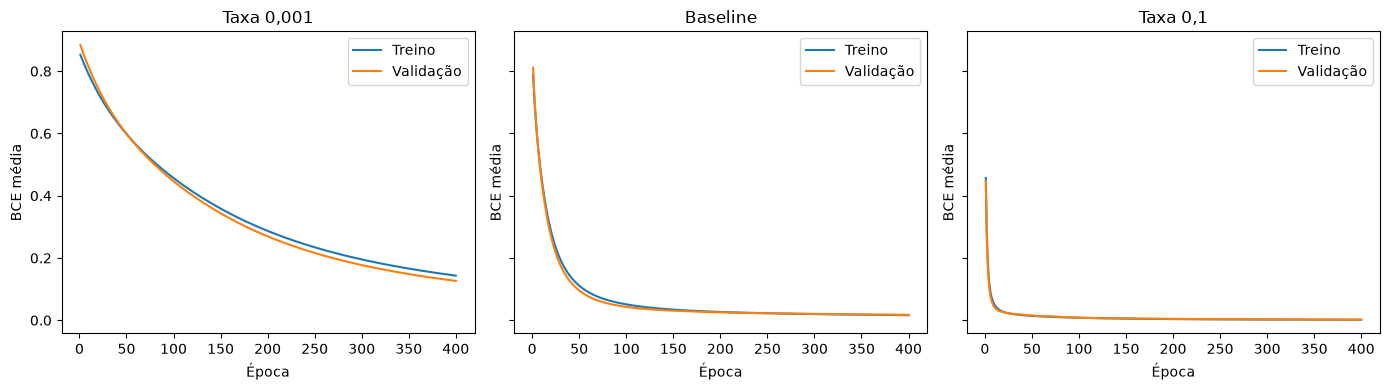

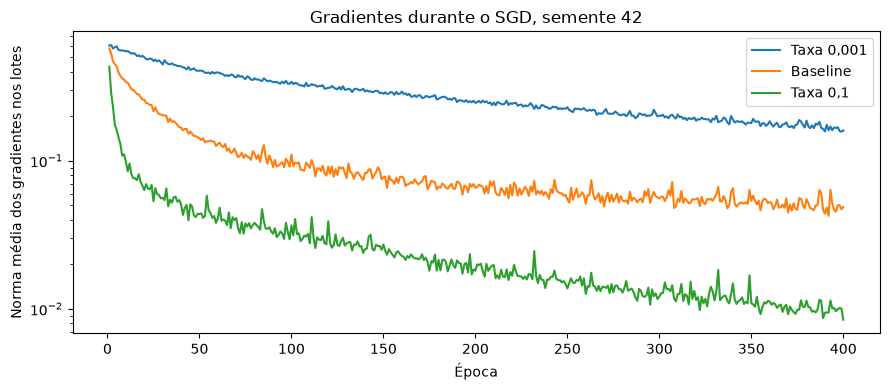

In [10]:
principais = ["Taxa 0,001","Baseline","Taxa 0,1"]
fig, axes = plt.subplots(1,3,figsize=(14,4),sharey=True)
for ax,nome in zip(axes,principais):
    h=historicos[nome]
    ax.plot(range(1,EPOCAS+1),h["treino"],label="Treino")
    ax.plot(range(1,EPOCAS+1),h["validacao"],label="Validação")
    ax.set(title=nome,xlabel="Época",ylabel="BCE média")
    ax.legend()
plt.tight_layout()
plt.show()

fig, ax=plt.subplots(figsize=(9,4))
for nome in principais:
    ax.plot(range(1,EPOCAS+1),historicos[nome]["norma_gradiente"],label=nome)
ax.set(xlabel="Época",ylabel="Norma média dos gradientes nos lotes",
       title="Gradientes durante o SGD, semente 42",yscale="log")
ax.legend()
plt.tight_layout()
plt.show()

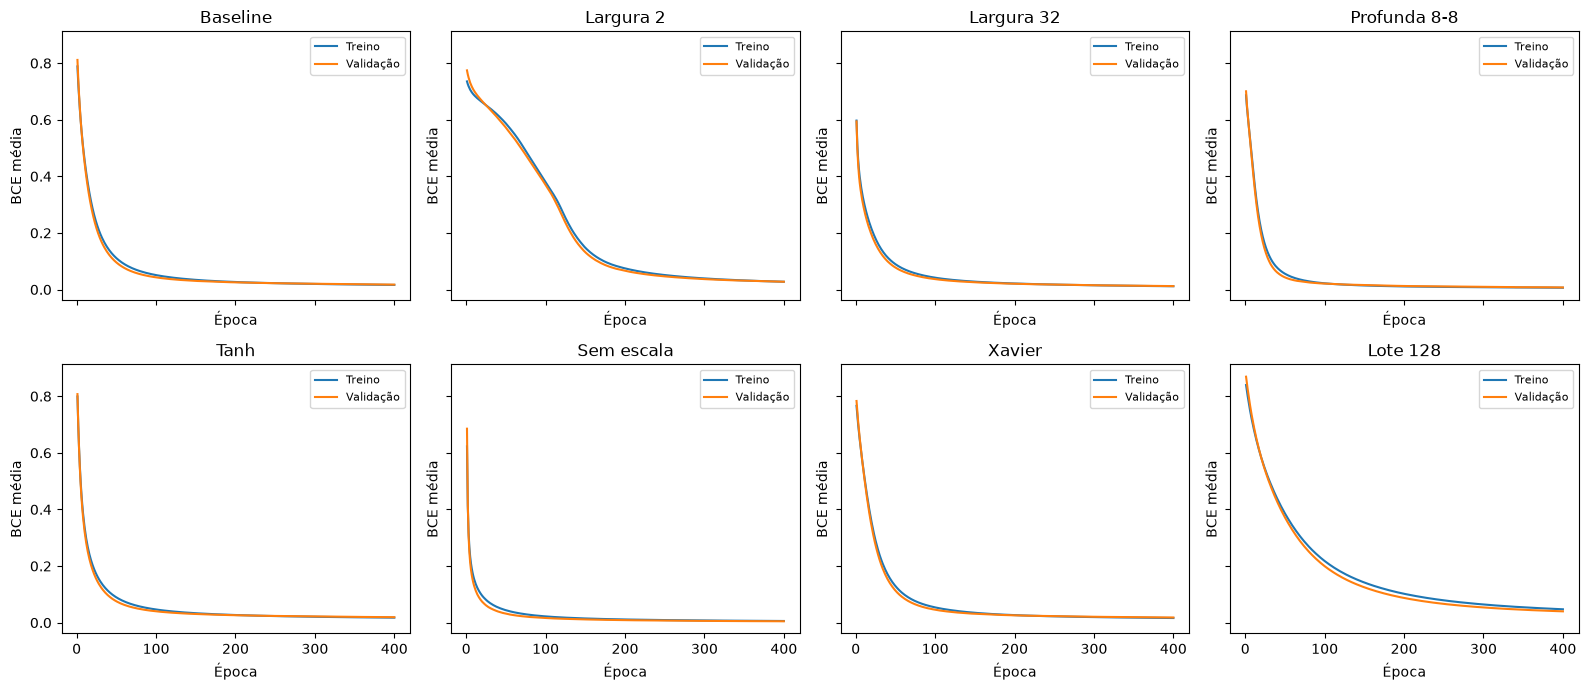

In [11]:
fig, axes = plt.subplots(2,4,figsize=(16,7),sharex=True,sharey=True)
outros = ["Baseline","Largura 2","Largura 32","Profunda 8-8",
          "Tanh","Sem escala","Xavier","Lote 128"]
for ax,nome in zip(axes.ravel(),outros):
    h=historicos[nome]
    ax.plot(range(1,EPOCAS+1),h["treino"],label="Treino")
    ax.plot(range(1,EPOCAS+1),h["validacao"],label="Validação")
    ax.set(title=nome,xlabel="Época",ylabel="BCE média")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. Decisão usando somente validação
Critério predefinido: menor **BCE média de validação** nas cinco sementes, na época 400.
A semente 42 foi escolhida previamente para a demonstração e para o teste final.
Não escolhemos a semente que acertou mais, nem ajustamos a taxa após olhar o teste.
A seleção usa a mesma validação várias vezes, o que pode trazer otimismo: a avaliação final fica separada.

In [12]:
escolhida = resumo["bce_media"].idxmin()
print("Configuração selecionada antes do teste:", escolhida)
principal_42 = resultados[resultados.seed==42].set_index("config")
display(principal_42[["tr_acc","val_acc","tr_bce","val_bce"]].round(5))
mva = modelos[escolhida]
xva = Xva_s if CONFIGS[escolhida]["padronizar"] else Xva
pva,_=forward(mva,xva)
cm_val = confusion_matrix(yva.ravel(),(pva.ravel()>=.5).astype(int),labels=[0,1])
print("Matriz de validação (linhas reais, colunas previstas):\n",cm_val)

Configuração selecionada antes do teste: Taxa 0,1


,tr_acc,val_acc,tr_bce,val_bce
config,,,,
Baseline,0.99629,0.99259,0.01625,0.01739
"Taxa 0,001",0.97153,0.98519,0.14332,0.12641
"Taxa 0,1",1.00000,1.00000,0.00158,0.00199
Largura 2,0.99629,0.99259,0.02752,0.02759
Largura 32,0.99629,0.99259,0.01161,0.01214
Profunda 8-8,0.99876,0.99630,0.00635,0.00736
Tanh,0.99629,0.99259,0.01769,0.01935
Sem escala,1.00000,1.00000,0.00589,0.00492
Xavier,0.99629,0.99259,0.01641,0.01825


Matriz de validação (linhas reais, colunas previstas):
 [[148   0]
 [  0 122]]


## 11. Teste final e análise de erros
Avaliamos **somente baseline e configuração selecionada**, semente 42, uma vez após a decisão.
O teste não é uma nova rodada de seleção entre todas as configurações.
Precisão, recall e F1 consideram a classe 1 como positiva.

,config,acc,precisao,recall,f1,bce
0,Baseline,0.98519,0.96825,1.0,0.98387,0.02954
1,"Taxa 0,1",0.99630,0.99187,1.0,0.99592,0.00510


Baseline : linhas = real, colunas = prevista
 [[144   4]
 [  0 122]]


,indice_dataset_limpo,classe_real,classe_prevista,p_classe_1
0,168,0,1,0.693997
1,143,0,1,0.878151
2,21,0,1,0.814976
3,106,0,1,0.669388


Taxa 0,1 : linhas = real, colunas = prevista
 [[147   1]
 [  0 122]]


,indice_dataset_limpo,classe_real,classe_prevista,p_classe_1
0,106,0,1,0.57176


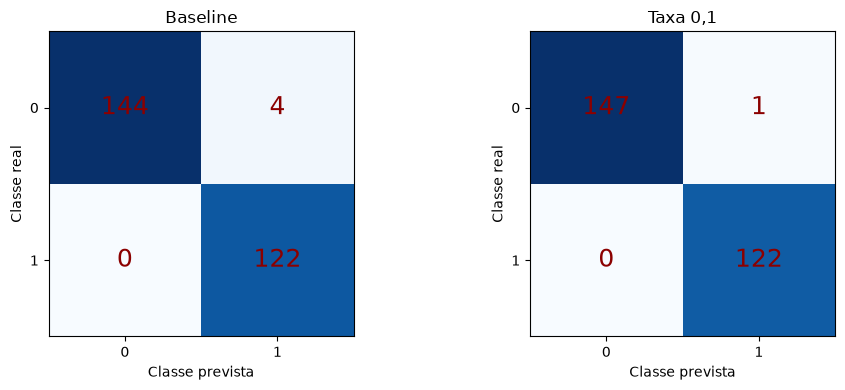

In [13]:
Xte_s = scaler.transform(Xte.T).T
teste_linhas, matrizes_teste, erros_teste = [], {}, {}
for nome in dict.fromkeys(["Baseline", escolhida]):
    modelo = modelos[nome]
    xx = Xte_s if CONFIGS[nome]["padronizar"] else Xte
    medidas = metricas(modelo,xx,yte)
    teste_linhas.append({"config":nome,**medidas})
    prob,_ = forward(modelo,xx)
    previsto=(prob.ravel()>=.5).astype(int)
    matrizes_teste[nome]=confusion_matrix(yte.ravel(),previsto,labels=[0,1])
    erros=np.flatnonzero(previsto!=yte.ravel())
    erros_teste[nome]=pd.DataFrame({"indice_dataset_limpo":i_te[erros],
        "classe_real":yte.ravel()[erros].astype(int),
        "classe_prevista":previsto[erros],"p_classe_1":prob.ravel()[erros]})
teste=pd.DataFrame(teste_linhas)
display(teste.round(5))
for nome,cm in matrizes_teste.items():
    print(nome,": linhas = real, colunas = prevista\n",cm)
    display(erros_teste[nome])
fig, axes=plt.subplots(1,len(matrizes_teste),figsize=(5*len(matrizes_teste),4),squeeze=False)
for ax,(nome,cm) in zip(axes.ravel(),matrizes_teste.items()):
    ax.imshow(cm,cmap="Blues")
    for (i,j),valor in np.ndenumerate(cm):
        ax.text(j,i,str(valor),ha="center",va="center",fontsize=18,color="darkred")
    ax.set(title=nome,xlabel="Classe prevista",ylabel="Classe real",xticks=[0,1],yticks=[0,1])
plt.tight_layout()
plt.show()

## 12. Interpretação e limitações
- Compare as taxas usando curvas e BCE, não apenas acurácia. Uma curva mais lenta com orçamento fixo sugere limitação de otimização, não necessariamente falta de capacidade.
- Verifique largura e profundidade sem pressupor que mais neurônios melhorarão os resultados.
- A ablação tanh mantém a escala inicial He para isolar a ativação. Isso não representa a melhor configuração possível de tanh.
- Lote 128 faz sete atualizações por época; lote 32 faz 26. A comparação fixa épocas, não quantidade de atualizações.
- Cinco sementes em uma única divisão avaliam inicialização e embaralhamento, não a incerteza entre partições.
- Ausência de grande gap não prova ausência de overfitting. Saturação de acurácia limita a distinção entre configurações.
- O experimento é educacional, com atributos já extraídos. Não processa imagens nem valida um sistema operacional de autenticação de cédulas.
- Usamos um protocolo predefinido nesta análise. O mesmo dataset e uma única partição não constituem um benchmark externo.
- Próximos passos: repetir divisões, testar outra base e comparar orçamento por atualizações. Não executar essas escolhas usando o teste atual como validação.

**Referências:** Notas da disciplina sobre MLP e backpropagation; Lohweg (2012), UCI, DOI 10.24432/C55P57.

### Resultados observados nesta execução
A taxa 0,001 teve acurácia média de validação de **96,44%**, contra **99,26%** da baseline e **100%** da taxa 0,1. As BCEs médias foram **0,16846**, **0,01581** e **0,00204**, respectivamente.
Neste orçamento, a taxa menor aprendeu mais lentamente. A taxa 0,1 não apresentou divergência e foi selecionada antes da avaliação final.

No teste da semente 42, a baseline teve **98,52%** de acurácia (4 erros), e a selecionada teve **99,63%** (1 erro).
Ambas tiveram recall da classe 1 de 100% nesta amostra. Isso não garante recall perfeito em outra população.

Nas ablações, duas e 32 unidades tiveram a mesma acurácia média da baseline, mas BCEs diferentes.
A rede profunda teve **99,85%** de acurácia média de validação. A base sem padronização teve BCE média **0,00457**, menor que a baseline.
Esse resultado não invalida a padronização: a escala interage com a taxa e muda os passos efetivos.
O lote 128 teve BCE **0,04340**, mas faz menos atualizações por época.

Os gradientes analíticos passaram na checagem numérica para ReLU e tanh (erro relativo na ordem de 10⁻¹¹).
A BCE do exemplo didático caiu de **0,566870** para **0,562994** após um passo.

In [14]:
# Exportação opcional dos resultados para reproduzir as tabelas deste notebook.
resultados.to_csv("resultados_validacao.csv",index=False)
teste.to_csv("resultados_teste.csv",index=False)
print("Tabelas exportadas. Os valores exibidos acima são os desta execução.")

Tabelas exportadas. Os valores exibidos acima são os desta execução.
